# Fil rouge ProtAnnotML · 1 — Des données IMGT au jeu d'apprentissage

> **Objectif** : définir précisément les tâches de ProtAnnotML, puis construire un jeu d'apprentissage **propre, vérifiable et traçable** : lecture des fichiers de référence IMGT (en-têtes, séquences avec gaps), règles de numérotation IMGT (gaps et insertions des CDR), étiquettes par résidu (domaine, FR/CDR, position IMGT), étiquettes par domaine (locus, gène, allèle, espèce), et ambiguïtés d'allèles. Tout le code est exporté dans le paquet `projet_protannotml/protannotml/`, réutilisé par les notebooks suivants.

| | |
|---|---|
| **Durée estimée** | 2 h 30 |
| **Prérequis** | Modules 2 (tokenisation), 9 (PLM, régions FR/CDR), 10 (NER, BIO) |
| **Librairies** | `numpy`, `matplotlib`, `pandas` |

> ⚠️ **Données.** Je n'ai pas accès aux fichiers IMGT dans cet environnement : les démonstrations utilisent un **générateur synthétique** qui imite la structure du répertoire de référence IMGT (loci, familles, gènes, allèles, espèces, longueurs des CDR, règles de gaps) avec des séquences **inventées** (préfixe `DEMO-`). Les fonctions de lecture sont écrites pour les vrais formats (FASTA IMGT/GENE-DB, AIRR d'IMGT/HighV-QUEST) et testées sur des enregistrements au même format. Tu remplaceras simplement le chemin des fichiers.

**Plan**

1. Les tâches de ProtAnnotML, formalisées
2. La numérotation IMGT : positions, gaps, insertions
3. Lire les fichiers de référence IMGT
4. Un répertoire de référence synthétique
5. Des séquences réarrangées et mutées aux constructions multi-domaines
6. Contrôle qualité, ambiguïtés d'allèles et export
7. Les vraies données : sorties AIRR d'IMGT/HighV-QUEST
8. Récapitulatif et exercices

In [1]:
import json
import sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
DATA = Path("data_protannotml"); DATA.mkdir(exist_ok=True)

## 1. Les tâches de ProtAnnotML, formalisées

IMGT/DomainGapAlign prend une séquence d'acides aminés, l'**aligne** sur le répertoire de référence IMGT et en déduit les domaines, la numérotation IMGT, les régions FR/CDR et les gènes/allèles les plus proches. ProtAnnotML doit apprendre les mêmes sorties. Avant tout code, on fixe le contrat :

**Entrée** : une séquence protéique, qui peut être un domaine V isolé, une chaîne (V + C), ou une construction (scFv VH–linker–VL, bispécifique…), éventuellement tronquée ou précédée d'un peptide signal.

| Tâche | Niveau | Sortie | Type de problème |
|---|---|---|---|
| T1 Délimitation des domaines | résidu | `B-V`, `I-V`, `B-C`, `I-C`, `O` | segmentation (BIO, module 10) |
| T2 Régions | résidu (dans un V) | FR1…FR4, CDR1…CDR3 | segmentation à ordre imposé |
| T3 Numérotation | résidu (dans un V) | position IMGT (`1`…`128`, `111.1`, `112.1`…) | alignement à un profil |
| T4 Identification | domaine V | locus, gène, allèle, espèce | classification (avec ambiguïtés) |

Trois remarques qui structurent tout le projet :

- **T2 et T3 sont fortement contraintes** : l'ordre des régions est fixe et les positions IMGT sont **croissantes** le long de la chaîne. Un modèle qui prédit chaque résidu indépendamment produira des sorties **invalides** (un CDR1 après un FR2, une position 40 après une position 45). Il faut un **décodage structuré** (Viterbi sous contraintes, notebook 3).
- **T4 est ambiguë par nature** : plusieurs allèles peuvent être **identiques** sur la partie observée, et après hypermutation somatique un domaine peut être à égale distance de deux gènes. La bonne cible est un **ensemble** d'étiquettes, et la métrique doit le savoir.
- **La référence actuelle est l'alignement.** Pour publier, il faut montrer où le modèle fait **mieux** que l'alignement (vitesse, séquences très mutées, espèces peu couvertes, constructions complexes) et où il fait **moins bien**. C'est le fil conducteur de l'évaluation (notebook 5).

## 2. La numérotation IMGT : positions, gaps, insertions

La numérotation unique IMGT du domaine V : FR1-IMGT 1–26, CDR1-IMGT 27–38, FR2-IMGT 39–55, CDR2-IMGT 56–65, FR3-IMGT 66–104, CDR3-IMGT 105–117, FR4-IMGT 118–128 ; positions conservées : 1st-CYS 23, CONSERVED-TRP 41, acide aminé hydrophobe 89, 2nd-CYS 104, J-PHE ou J-TRP 118.

Quand un CDR est plus court que sa longueur maximale, les positions **non occupées** (gaps) sont retirées **au sommet de la boucle**, dans un ordre fixé : CDR1 : 33, 32, 34, 31, 35, 30, 36 ; CDR2 : 61, 60, 62, 59, 63, 58, 64, 57, 65, 56 ; CDR3 : 111, 112, 110, 113, 109, 114… Un CDR3 de plus de 13 résidus reçoit des **insertions** entre 111 et 112, dans l'ordre 112.1, 111.1, 112.2, 111.2… ; le long de la chaîne, l'ordre est donc 111, 111.1, 111.2, …, 112.2, 112.1, 112.

In [2]:
"""IMGT unique numbering for V domains: regions, CDR gap/insertion rules, FASTA headers, AIRR rows."""
from collections import defaultdict
from dataclasses import dataclass

REGIONS = [("FR1", 1, 26), ("CDR1", 27, 38), ("FR2", 39, 55), ("CDR2", 56, 65),
           ("FR3", 66, 104), ("CDR3", 105, 117), ("FR4", 118, 128)]
REGION_NAMES = [r for r, _, _ in REGIONS]
ANCHORS = {23: "1st-CYS", 41: "CONSERVED-TRP", 89: "hydrophobic", 104: "2nd-CYS", 118: "J-TRP/PHE"}
CDR_GAP_ORDER = {
    "CDR1": [33, 32, 34, 31, 35, 30, 36],
    "CDR2": [61, 60, 62, 59, 63, 58, 64, 57, 65, 56],
    "CDR3": [111, 112, 110, 113, 109, 114, 108, 115, 107, 116, 106, 117, 105],
}


def parse_pos(p):
    """'111.2' -> (111, 2); '45' or 45 -> (45, 0)."""
    s = str(p)
    if "." in s:
        base, ins = s.split(".")
        return int(base), int(ins)
    return int(s), 0


def pos_key(p):
    """Sort key giving the order of IMGT positions along the chain (111, 111.1, 111.2, ..., 112.2, 112.1, 112)."""
    base, ins = parse_pos(p)
    if ins == 0:
        return (base, 0, 0)
    if base == 111:
        return (111, 1, ins)
    if base == 112:
        return (111, 2, -ins)
    raise ValueError(f"insertions are only defined at 111/112 here, got {p}")


def region_of(pos):
    base, _ = parse_pos(pos)
    for name, start, end in REGIONS:
        if start <= base <= end:
            return name
    raise ValueError(f"position {pos} outside the V domain (1-128)")


def cdr_positions(region, length):
    """Occupied IMGT positions (chain order) of a CDR of a given length."""
    start, end = next((s, e) for r, s, e in REGIONS if r == region)
    full = list(range(start, end + 1))
    if length <= len(full):
        n_gaps = len(full) - length
        order = CDR_GAP_ORDER[region]
        if n_gaps > len(order):
            raise ValueError(f"{region} of length {length} is shorter than this table allows")
        gaps = set(order[:n_gaps])
        return [str(p) for p in full if p not in gaps]
    if region != "CDR3":
        raise ValueError(f"{region} longer than {len(full)} is not handled here")
    insertions, k = [], 1
    while len(insertions) < length - len(full):
        insertions.append(f"112.{k}")
        if len(insertions) < length - len(full):
            insertions.append(f"111.{k}")
        k += 1
    return sorted([str(p) for p in full] + insertions, key=pos_key)

Toujours **tester** ces règles sur les exemples de la documentation avant de construire quoi que ce soit dessus : une erreur ici contaminerait toutes les étiquettes.

Le notebook exporte le code dans `projet_protannotml/protannotml/`. Pour l'importer depuis les autres notebooks (et ici), on ajoute le dossier du projet au chemin Python :

In [3]:
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))
from protannotml.imgt import cdr_positions, pos_key, region_of, parse_pos, REGIONS, ANCHORS

missing = lambda region, L, full: sorted(set(map(str, full)) - set(cdr_positions(region, L)), key=pos_key)
assert missing("CDR1", 11, range(27, 39)) == ["33"]
assert missing("CDR1", 5, range(27, 39)) == [str(p) for p in range(30, 37)]
assert missing("CDR2", 9, range(56, 66)) == ["61"]
assert missing("CDR2", 0, range(56, 66)) == [str(p) for p in range(56, 66)]
assert cdr_positions("CDR3", 14) == ["105", "106", "107", "108", "109", "110", "111", "112.1", "112", "113", "114", "115", "116", "117"]
assert cdr_positions("CDR3", 16)[6:10] == ["111", "111.1", "112.2", "112.1"]
for L in [5, 8, 13, 15, 20]:
    print(f"CDR3 length {L:2d}: {' '.join(cdr_positions('CDR3', L))}")
print("all numbering tests passed")

CDR3 length  5: 105 106 107 116 117
CDR3 length  8: 105 106 107 108 114 115 116 117
CDR3 length 13: 105 106 107 108 109 110 111 112 113 114 115 116 117
CDR3 length 15: 105 106 107 108 109 110 111 111.1 112.1 112 113 114 115 116 117
CDR3 length 20: 105 106 107 108 109 110 111 111.1 111.2 111.3 112.4 112.3 112.2 112.1 112 113 114 115 116 117
all numbering tests passed


## 3. Lire les fichiers de référence IMGT

Les fichiers de référence d'IMGT/GENE-DB (par exemple `IMGTGENE-DB-ReferenceSequences.fasta-AA-WithGaps-F+ORF+inframeP`) ont un en-tête à 15 champs séparés par `|` : numéro d'accession IMGT/LIGM-DB, nom du gène et de l'allèle, espèce, fonctionnalité, label (par exemple `V-REGION`), positions, nombre de nucléotides, codon de départ, nucléotides ajoutés en 5' et en 3', corrections, nombre d'acides aminés, nombre de caractères (acides aminés + gaps), partiel, complémentaire inverse. Dans les fichiers « WithGaps », les gaps IMGT sont présents : **l'indice d'un caractère dans la séquence est sa position IMGT**.

In [4]:
IMGT_FIELDS = ["accession", "allele", "species", "functionality", "label", "positions", "n_nt",
               "codon_start", "added_5", "added_3", "corrections", "n_aa", "n_chars", "partial", "revcomp"]


@dataclass
class ImgtRecord:
    fields: dict
    seq: str

    @property
    def allele(self):
        return self.fields["allele"]

    @property
    def gene(self):
        return self.fields["allele"].split("*")[0]

    @property
    def species(self):
        return self.fields["species"]

    @property
    def locus(self):
        return self.gene[:3] if self.gene[:2] in ("IG", "TR") else self.gene.split("-")[1][:3]


def parse_imgt_header(header):
    parts = [p.strip() for p in header.lstrip(">").split("|")]
    parts += [""] * (len(IMGT_FIELDS) - len(parts))
    return dict(zip(IMGT_FIELDS, parts))


def read_imgt_fasta(lines):
    """Yield ImgtRecord from an iterable of lines (an open file or a list of strings)."""
    header, chunks = None, []
    for line in lines:
        line = line.rstrip("\n")
        if line.startswith(">"):
            if header is not None:
                yield ImgtRecord(parse_imgt_header(header), "".join(chunks))
            header, chunks = line, []
        elif line.strip():
            chunks.append(line.strip())
    if header is not None:
        yield ImgtRecord(parse_imgt_header(header), "".join(chunks))


def gapped_to_positions(gapped, first_position=1):
    """IMGT-gapped V-REGION (one char per IMGT position, '.' = gap) -> [(position, aa)]."""
    return [(str(i + first_position), aa) for i, aa in enumerate(gapped) if aa != "."]


def allele_key(species, allele):
    """Allele names are only unique within a species: always key alleles by (species, name)."""
    return f"{species}|{allele}"

Exemple sur deux enregistrements au format exact, avec des séquences **fictives** (qui respectent les ancres, mais ne correspondent à aucun allèle réel) :

In [5]:
from protannotml.imgt import read_imgt_fasta, gapped_to_positions

example = """>DEMO00001|DEMO-IGHV1-1*01|Homo sapiens|F|V-REGION|1..294|294 nt|1| | | |98 AA|98+8=106| | |
EVQLVESGA.ELVRPGESLKLSCKTSGFSL....SNYGISWVRQPPGKGLEWLGWISPYN..GDTNYAPKFK.GRATLSVDKSKNTVYLQMNSLKAEDTAIYYCAR
>DEMO00002|DEMO-IGKV1-1*01|Homo sapiens|F|V-REGION|1..285|270 nt|1| | | |90 AA|90+16=106| | |
EIVLTQSPATMSVTPGERATLSCRSSESV......TDLVAWYQQRPGQSPRLLIYDA.......SNRATGIPA.RFSGSRSG..TEYTLKISRVEAEDVGVYYCQQ
"""
for rec in read_imgt_fasta(example.splitlines()):
    pos = gapped_to_positions(rec.seq)
    by_region = defaultdict(str)
    for p, aa in pos:
        by_region[region_of(p)] += aa
    anchors = {a: dict(pos).get(str(a), "-") for a in (23, 41, 89, 104)}
    print(rec.allele, "|", rec.species, "|", rec.fields["functionality"], "| anchors:", anchors)
    print("   ", {r: s for r, s in by_region.items()})

DEMO-IGHV1-1*01 | Homo sapiens | F | anchors: {23: 'C', 41: 'W', 89: 'L', 104: 'C'}
    {'FR1': 'EVQLVESGAELVRPGESLKLSCKTS', 'CDR1': 'GFSLSNYG', 'FR2': 'ISWVRQPPGKGLEWLGW', 'CDR2': 'ISPYNGDT', 'FR3': 'NYAPKFKGRATLSVDKSKNTVYLQMNSLKAEDTAIYYC', 'CDR3': 'AR'}
DEMO-IGKV1-1*01 | Homo sapiens | F | anchors: {23: 'C', 41: 'W', 89: 'L', 104: 'C'}
    {'FR1': 'EIVLTQSPATMSVTPGERATLSCRSS', 'CDR1': 'ESVTDL', 'FR2': 'VAWYQQRPGQSPRLLIY', 'CDR2': 'DAS', 'FR3': 'NRATGIPARFSGSRSGTEYTLKISRVEAEDVGVYYC', 'CDR3': 'QQ'}


> ✅ **Vérification systématique** sur les vrais fichiers : les ancres (C23, W41, C104) doivent être présentes pour les gènes fonctionnels ; un écart signale un décalage (séquence partielle en 5', champ 14) ou un pseudogène. Les enregistrements partiels en 5' sont à **écarter** ou à traiter à part : rien ne garantit alors que le premier caractère soit la position 1.

## 4. Un répertoire de référence synthétique

Pour développer et tester sans les données, on génère un répertoire qui a la **même structure statistique** que le vrai : locus → famille (partagée entre espèces, comme les familles orthologues) → espèce → gène → allèles (1 à 3 mutations ponctuelles). Les longueurs de CDR1/CDR2 sont fixées par famille, les frameworks sont plus conservés que les CDR, les ancres sont respectées, et quelques pseudogènes contiennent un codon stop (`*`). L'humain et le macaque sont proches, la souris plus éloignée : cela permettra de tester la généralisation **à une espèce non vue**.

In [6]:
"""Synthetic IMGT-like reference directory and rearranged sequences (fictional data for development)."""
import numpy as np

from protannotml.imgt import REGIONS, cdr_positions, region_of, pos_key, ANCHORS

FR_RES = list("GSAVLTEQKPRDIFYN")
CDR_RES = list("YSGDNTAWRFHLK")
LOCI = {
    "IGH": dict(cdr1=[8, 8, 8, 9, 10], cdr2=[8, 8, 7, 10], fr_gaps=[10, 73], cdr3=(8, 22), cdr3_start="AR", j_anchor="W", c_len=98),
    "IGK": dict(cdr1=[6, 6, 7, 11, 12], cdr2=[3, 3], fr_gaps=[], cdr3=(7, 11), cdr3_start="QQ", j_anchor="F", c_len=102),
    "IGL": dict(cdr1=[8, 9, 6], cdr2=[3, 7], fr_gaps=[10], cdr3=(8, 13), cdr3_start="QS", j_anchor="F", c_len=100),
    "TRB": dict(cdr1=[5, 5, 6], cdr2=[6, 5], fr_gaps=[10, 73], cdr3=(10, 17), cdr3_start="AS", j_anchor="F", c_len=110),
}
SPECIES_DIVERGENCE = {"Homo sapiens": 0.04, "Macaca mulatta": 0.05, "Mus musculus": 0.16}
ANCHOR_AA = {23: "C", 41: "W", 104: "C"}


def _draw(rng, region):
    return str(rng.choice(CDR_RES if region.startswith("CDR") else FR_RES))


def mutate(seq, rng, rate_fr, rate_cdr, protect=(23, 41, 89, 104)):
    """Point mutations on a {position: aa} dict, CDR positions mutating faster; anchors protected."""
    out = dict(seq)
    for p, aa in seq.items():
        base = int(str(p).split(".")[0])
        if base in protect:
            continue
        region = region_of(p)
        if rng.random() < (rate_cdr if region.startswith("CDR") else rate_fr):
            new = _draw(rng, region)
            while new == aa:
                new = _draw(rng, region)
            out[p] = new
    return out


def _v_ancestor(rng):
    """Full-length V-REGION ancestor (positions 1-104, CDR1/CDR2 at maximum length)."""
    seq = {}
    for name, start, end in REGIONS[:5]:
        for p in range(start, end + 1):
            seq[str(p)] = ANCHOR_AA.get(p, _draw(rng, name))
    seq["89"] = str(rng.choice(list("LVIM")))
    return seq


def _restrict(seq, locus_cfg, cdr1_len, cdr2_len):
    keep = set(cdr_positions("CDR1", cdr1_len)) | set(cdr_positions("CDR2", cdr2_len))
    out = {}
    for p, aa in seq.items():
        region = region_of(p)
        if region in ("CDR1", "CDR2") and p not in keep:
            continue
        if int(p) in locus_cfg["fr_gaps"]:
            continue
        out[p] = aa
    return out


def to_gapped(seq, last=104):
    return "".join(seq.get(str(p), ".") for p in range(1, last + 1))


def make_reference(seed=0, n_families=4, genes_per_family=(3, 6), max_alleles=3, pseudo_rate=0.06):
    """Return a list of dicts: allele, gene, family, locus, species, functionality, positions {pos: aa}."""
    rng = np.random.default_rng(seed)
    refs, j_genes, c_domains = [], [], []
    for locus, cfg in LOCI.items():
        locus_anc = _v_ancestor(rng)
        for fam in range(1, n_families + 1):
            fam_anc = mutate(locus_anc, rng, 0.25, 0.55)
            cdr1, cdr2 = int(rng.choice(cfg["cdr1"])), int(rng.choice(cfg["cdr2"]))
            n_genes = int(rng.integers(*genes_per_family, endpoint=True))
            gene_ancs = [mutate(fam_anc, rng, 0.07, 0.25) for _ in range(n_genes)]
            for species, div in SPECIES_DIVERGENCE.items():
                for g, gene_anc in enumerate(gene_ancs, start=1):
                    if rng.random() < 0.15:          # gene absent from this species
                        continue
                    gene_seq = _restrict(mutate(gene_anc, rng, div, 2.5 * div), cfg, cdr1, cdr2)
                    gene = f"DEMO-{locus}V{fam}-{g}"
                    seen = []
                    for a in range(1, int(rng.integers(1, max_alleles, endpoint=True)) + 1):
                        seq = dict(gene_seq)
                        if a > 1:
                            for p in rng.choice([p for p in seq if int(p) not in ANCHOR_AA], size=int(rng.integers(1, 4)), replace=False):
                                seq[str(p)] = _draw(rng, region_of(p))
                        func = "F"
                        if rng.random() < pseudo_rate:
                            seq[str(rng.choice([p for p in seq if int(p) > 30]))] = "*"
                            func = "P"
                        refs.append(dict(allele=f"{gene}*{a:02d}", gene=gene, family=f"{locus}V{fam}", locus=locus,
                                         species=species, functionality=func, positions=seq))
                        seen.append(seq)
        for j in range(1, 5):                         # J genes: FR4-IMGT 118-128
            j_anc = [cfg["j_anchor"], "G"] + [str(rng.choice(FR_RES))] + ["G"] + [str(rng.choice(FR_RES)) for _ in range(7)]
            for species, div in SPECIES_DIVERGENCE.items():
                fr4 = {str(118 + i): aa for i, aa in enumerate(j_anc)}
                fr4 = mutate(fr4, rng, div, div, protect=(118, 119, 121))
                j_genes.append(dict(allele=f"DEMO-{locus}J{j}*01", gene=f"DEMO-{locus}J{j}", locus=locus, species=species, positions=fr4))
        c_anc = "".join(rng.choice(FR_RES, size=cfg["c_len"]))
        c_anc = c_anc[:24] + "C" + c_anc[25:80] + "C" + c_anc[81:]
        for species, div in SPECIES_DIVERGENCE.items():
            c = "".join(ch if (i in (24, 80) or rng.random() > div) else str(rng.choice(FR_RES)) for i, ch in enumerate(c_anc))
            c_domains.append(dict(name=f"DEMO-{locus}C", locus=locus, species=species, seq=c))
    return refs, j_genes, c_domains


def write_imgt_fasta(refs, path):
    """Write V-REGION alleles in the IMGT/GENE-DB AA-WithGaps layout (15 '|' fields)."""
    with open(path, "w") as f:
        for i, r in enumerate(refs, start=1):
            gapped = to_gapped(r["positions"])
            n_aa = sum(c != "." for c in gapped)
            fields = [f"DEMO{i:05d}", r["allele"], r["species"], r["functionality"], "V-REGION",
                      f"1..{3 * n_aa}", f"{3 * n_aa} nt", "1", " ", " ", " ", f"{n_aa} AA",
                      f"{n_aa}+{len(gapped) - n_aa}={len(gapped)}", " ", " "]
            f.write(">" + "|".join(fields) + "|\n" + gapped + "\n")

In [7]:
from protannotml.synth import make_reference, write_imgt_fasta, LOCI, SPECIES_DIVERGENCE
from protannotml.imgt import read_imgt_fasta

refs, j_genes, c_domains = make_reference(seed=0)
write_imgt_fasta(refs, DATA / "DEMO-ReferenceSequences.fasta-AA-WithGaps")
reloaded = list(read_imgt_fasta(open(DATA / "DEMO-ReferenceSequences.fasta-AA-WithGaps")))
assert [r.allele for r in reloaded] == [r["allele"] for r in refs]          # round trip through the IMGT format

df_ref = pd.DataFrame([{k: v for k, v in r.items() if k != "positions"} for r in refs])
print(f"{len(refs)} V alleles, {df_ref.gene.nunique()} genes, {len(j_genes)} J alleles, {len(c_domains)} C domains")
print(df_ref.groupby(["locus", "species"]).allele.count().unstack())
print("functionality:", dict(Counter(df_ref.functionality)))
print(open(DATA / "DEMO-ReferenceSequences.fasta-AA-WithGaps").read()[:330])

366 V alleles, 73 genes, 48 J alleles, 12 C domains
species  Homo sapiens  Macaca mulatta  Mus musculus
locus                                              
IGH                36              27            30
IGK                32              25            30
IGL                30              28            23
TRB                34              37            34
functionality: {'F': 347, 'P': 19}
>DEMO00001|DEMO-IGHV1-1*01|Homo sapiens|F|V-REGION|1..288|288 nt|1| | | |96 AA|96+8=104| | |
YRFLQPEGA.PYKKNDRKKYLFCGEFRWDF....YSWDFEWGDSYRKRLPFERNSFFAH..RTYWAPDFKEL.QDYKYKSRPPTNFKLMQTYRVQPGFEFEITC
>DEMO00002|DEMO-IGHV1-1*02|Homo sapiens|F|V-REGION|1..288|288 nt|1| | | |96 AA|96+8=104| | |
YRFLQPEGA.PYKKNDRKKYLFCGEFRWDF....YSWDF


Une vue « par position » montre ce qu'un modèle devra apprendre : la **variabilité** (entropie de Shannon des acides aminés) le long des positions IMGT, sur les allèles IGH. Les CDR sont nettement plus variables que les frameworks, les ancres sont à zéro, et les positions des gaps du sommet des boucles sont souvent vides.

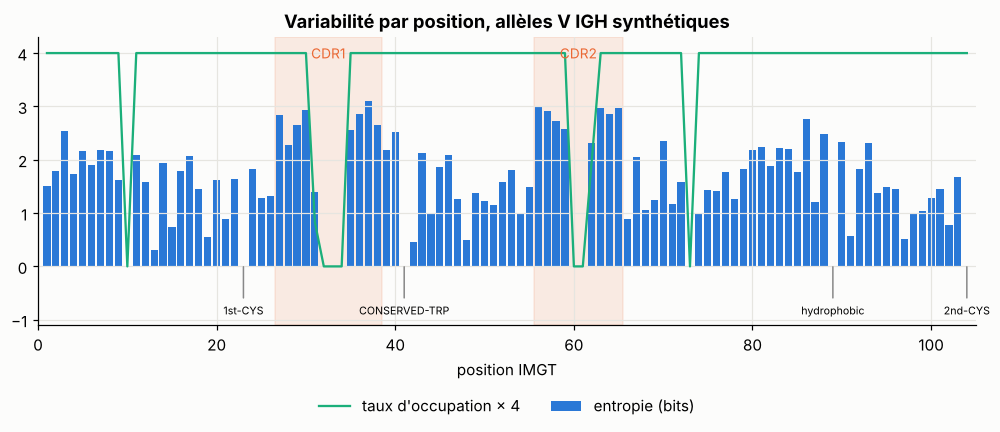

In [8]:
def position_entropy(alleles, positions):
    ent, occ = [], []
    for p in positions:
        aas = [a["positions"][p] for a in alleles if p in a["positions"]]
        occ.append(len(aas) / len(alleles))
        if not aas:
            ent.append(np.nan); continue
        c = np.array(list(Counter(aas).values()), dtype=float) / len(aas)
        ent.append(-(c * np.log2(c)).sum())
    return np.array(ent), np.array(occ)

igh = [r for r in refs if r["locus"] == "IGH" and r["functionality"] == "F"]
positions = [str(p) for p in range(1, 105)]
ent, occ = position_entropy(igh, positions)
fig, ax = plt.subplots(figsize=(11, 3.4))
for k, (name, s, e) in enumerate(REGIONS[:5]):
    if name.startswith("CDR"):
        ax.axvspan(s - 0.5, e + 0.5, color=PALETTE[1], alpha=0.12)
        ax.text((s + e) / 2, 3.9, name, ha="center", color=PALETTE[1], fontsize=9)
ax.bar(range(1, 105), ent, color=PALETTE[0], width=0.8, label="entropie (bits)")
ax.plot(range(1, 105), occ * 4, color=PALETTE[2], lw=1.5, label="taux d'occupation × 4")
for a, name in ANCHORS.items():
    if a <= 104:
        ax.annotate(name, (a, 0.05), xytext=(a, -0.9), ha="center", fontsize=7, arrowprops=dict(arrowstyle="-", color="#888"))
ax.set_xlim(0, 105); ax.set_ylim(-1.1, 4.3); ax.set_xlabel("position IMGT")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
ax.set_title("Variabilité par position, allèles V IGH synthétiques")
plt.show()

## 5. Des séquences réarrangées et mutées aux constructions multi-domaines

Le répertoire de référence contient des **germlines**. Les séquences que ProtAnnotML annotera (anticorps thérapeutiques, séquences de répertoires) sont **réarrangées** (V + CDR3 + J) et **mutées** (hypermutation somatique, ingénierie). Si l'on n'entraîne que sur des germlines, le modèle apprend à reconnaître des séquences « parfaites » et s'effondre sur des séquences mutées. La vraie source d'entraînement sera donc IMGT/LIGM-DB et les sorties d'IMGT/HighV-QUEST (section 7) ; ici on simule :

1. un réarrangement : allèle V fonctionnel + CDR3 de longueur variable (numérotée selon les règles de la section 2) + J ;
2. une hypermutation à un taux tiré entre 0 et 12 %, trois fois plus forte dans les CDR ;
3. des imperfections réalistes : un peptide signal en N-terminal (15 % des cas), une troncature de 1 à 5 résidus au début du FR1 (15 %) ;
4. trois types de constructions : domaine V seul, scFv (VH–(G4S)₃–VL), chaîne V + C.

Chaque résidu reçoit trois étiquettes (domaine BIO, région, position IMGT) et chaque domaine V ses métadonnées (locus, espèce, gène et allèle V, gène J, taux de mutation).

In [9]:
LINKER = "GGGGS" * 3
SIGNAL_RES = list("MKLLAVLLGLSAQPAMA")


def rearrange(rng, v, js, shm_rate):
    """V allele + numbered CDR3 + J (FR4) -> list of (position, aa), then somatic hypermutation."""
    cfg = LOCI[v["locus"]]
    cdr3_len = int(rng.integers(*cfg["cdr3"], endpoint=True))
    cdr3_pos = cdr_positions("CDR3", cdr3_len)
    cdr3_aa = list(cfg["cdr3_start"]) + [str(rng.choice(CDR_RES)) for _ in range(cdr3_len - 2)]
    j = js[int(rng.integers(len(js)))]
    seq = dict(v["positions"])
    seq.update(zip(cdr3_pos, cdr3_aa))
    seq.update(j["positions"])
    seq = mutate(seq, rng, shm_rate / 2, 1.5 * shm_rate, protect=(23, 41, 104, 118, 119, 121))
    return sorted(seq.items(), key=lambda kv: pos_key(kv[0])), j


def _v_part(rng, refs_by_ls, js_by_ls, locus, species, truncate):
    v = refs_by_ls[(locus, species)][int(rng.integers(len(refs_by_ls[(locus, species)])))]
    shm = float(rng.uniform(0, 0.12))
    residues, j = rearrange(rng, v, js_by_ls[(locus, species)], shm)
    if truncate:
        residues = residues[int(rng.integers(1, 6)):]
    meta = dict(type="V", locus=locus, species=species, v_allele=v["allele"], v_gene=v["gene"],
                j_gene=j["gene"], shm_rate=round(shm, 4))
    return residues, meta


def make_example(rng, refs_by_ls, js_by_ls, c_by_ls, kind, species):
    """One sequence with per-residue labels (domain BIO, region, IMGT position) and per-domain metadata."""
    seq, dom, reg, pos, domains = [], [], [], [], []

    def add_other(text, region="O"):
        for aa in text:
            seq.append(aa); dom.append("O"); reg.append(region); pos.append("-")

    def add_v(locus, truncate=False):
        residues, meta = _v_part(rng, refs_by_ls, js_by_ls, locus, species, truncate)
        meta["start"] = len(seq)
        for i, (p, aa) in enumerate(residues):
            seq.append(aa); dom.append("B-V" if i == 0 else "I-V"); reg.append(region_of(p)); pos.append(p)
        meta["end"] = len(seq)
        domains.append(meta)

    def add_c(locus):
        c = c_by_ls[(locus, species)]
        start = len(seq)
        for i, aa in enumerate(c["seq"]):
            seq.append(aa); dom.append("B-C" if i == 0 else "I-C"); reg.append("C"); pos.append("-")
        domains.append(dict(type="C", locus=locus, species=species, start=start, end=len(seq)))

    if rng.random() < 0.15:
        add_other("".join(rng.choice(SIGNAL_RES, size=int(rng.integers(15, 22)))))
    truncate = rng.random() < 0.15
    light = "IGK" if rng.random() < 0.6 else "IGL"
    if kind == "V":
        add_v(str(rng.choice(["IGH", "IGH", light, "TRB"])), truncate)
    elif kind == "scFv":
        add_v("IGH", truncate); add_other(LINKER); add_v(light)
    elif kind == "V+C":
        locus = str(rng.choice(["IGH", light, "TRB"]))
        add_v(locus, truncate); add_c(locus)
    return dict(kind=kind, species=species, seq="".join(seq), domain_tags=dom, regions=reg, imgt_pos=pos, domains=domains)


def make_dataset(refs, j_genes, c_domains, n=6000, seed=1, kinds=(("V", 0.5), ("scFv", 0.25), ("V+C", 0.25))):
    rng = np.random.default_rng(seed)
    refs_by_ls, js_by_ls = {}, {}
    for r in refs:
        if r["functionality"] == "F":
            refs_by_ls.setdefault((r["locus"], r["species"]), []).append(r)
    for j in j_genes:
        js_by_ls.setdefault((j["locus"], j["species"]), []).append(j)
    c_by_ls = {(c["locus"], c["species"]): c for c in c_domains}
    names, probs = zip(*kinds)
    species_list = list(SPECIES_DIVERGENCE)
    data = []
    for i in range(n):
        ex = make_example(rng, refs_by_ls, js_by_ls, c_by_ls, str(rng.choice(names, p=probs)), str(rng.choice(species_list)))
        ex["id"] = f"seq{i:05d}"
        data.append(ex)
    return data

In [10]:
from protannotml.synth import make_dataset

data = make_dataset(refs, j_genes, c_domains, n=6000, seed=1)
ex = next(d for d in data if d["kind"] == "scFv")
print(ex["id"], ex["kind"], ex["species"], "length", len(ex["seq"]))
for d in ex["domains"]:
    print("  ", {k: v for k, v in d.items()})
print(pd.DataFrame({"aa": list(ex["seq"]), "domain": ex["domain_tags"], "region": ex["regions"], "imgt": ex["imgt_pos"]}).iloc[100:135].T.to_string(header=False))

seq00000 scFv Mus musculus length 267
   {'type': 'V', 'locus': 'IGH', 'species': 'Mus musculus', 'v_allele': 'DEMO-IGHV4-2*01', 'v_gene': 'DEMO-IGHV4-2', 'j_gene': 'DEMO-IGHJ1', 'shm_rate': 0.0161, 'start': 21, 'end': 141}
   {'type': 'V', 'locus': 'IGK', 'species': 'Mus musculus', 'v_allele': 'DEMO-IGKV1-4*01', 'v_gene': 'DEMO-IGKV1-4', 'j_gene': 'DEMO-IGKJ4', 'shm_rate': 0.06, 'start': 156, 'end': 267}
aa        Y    M    L    T    F    D    V    D    P    G    S    R    F    Y    I    R    C     A     R     T     L     G     A     D     Y     F     Y     D     A     A    W    G    Y    G    V
domain  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V  I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V   I-V  I-V  I-V  I-V  I-V  I-V
region  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  FR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  CDR3  FR4  FR4  FR4  FR4  FR4
imgt  

Visualisons quelques exemples : une ligne par séquence, une couleur par région.

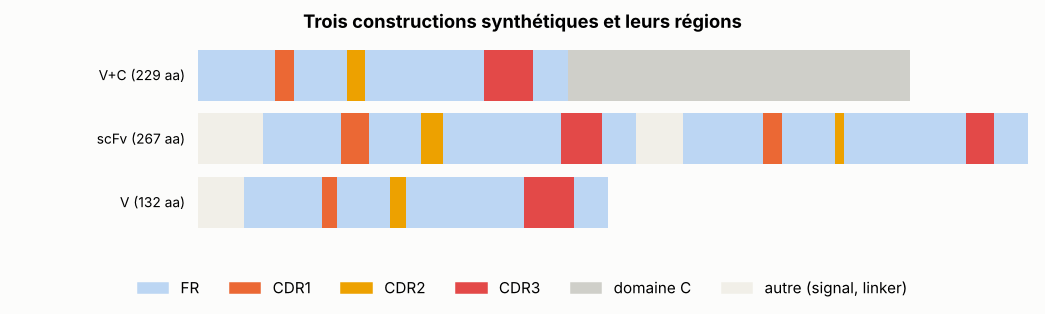

In [11]:
REG_COLORS = {"FR1": "#bcd6f3", "FR2": "#bcd6f3", "FR3": "#bcd6f3", "FR4": "#bcd6f3",
              "CDR1": PALETTE[1], "CDR2": PALETTE[3], "CDR3": PALETTE[7], "C": "#cfcfc9", "O": "#f1efe8"}
show = [next(d for d in data if d["kind"] == k and (k != "V" or d["domain_tags"][0] == "O")) for k in ["V", "scFv", "V+C"]]
fig, ax = plt.subplots(figsize=(12, 2.4))
for row, d in enumerate(show):
    for i, r in enumerate(d["regions"]):
        ax.add_patch(plt.Rectangle((i, row), 1, 0.8, color=REG_COLORS[r], lw=0))
    ax.text(-4, row + 0.4, f"{d['kind']} ({len(d['seq'])} aa)", ha="right", va="center", fontsize=9)
handles = [plt.Rectangle((0, 0), 1, 1, color=REG_COLORS[k]) for k in ["FR1", "CDR1", "CDR2", "CDR3", "C", "O"]]
ax.legend(handles, ["FR", "CDR1", "CDR2", "CDR3", "domaine C", "autre (signal, linker)"], ncols=6, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_xlim(-60, max(len(d["seq"]) for d in show) + 2); ax.set_ylim(-0.2, 3); ax.axis("off")
ax.set_title("Trois constructions synthétiques et leurs régions")
plt.show()

## 6. Contrôle qualité, ambiguïtés d'allèles et export

Trois vérifications avant d'entraîner quoi que ce soit.

**(a) Cohérence des étiquettes** : chaque domaine V doit avoir des positions strictement croissantes, des régions dans l'ordre, et ses ancres conservées. Ces assertions sont peu coûteuses et attrapent la plupart des bugs de préparation.

In [12]:
def check_example(ex):
    from protannotml.imgt import REGION_NAMES
    n = len(ex["seq"])
    assert len(ex["domain_tags"]) == len(ex["regions"]) == len(ex["imgt_pos"]) == n
    for d in ex["domains"]:
        if d["type"] != "V":
            continue
        pos = ex["imgt_pos"][d["start"]:d["end"]]
        keys = [pos_key(p) for p in pos]
        assert keys == sorted(keys) and len(set(keys)) == len(keys), "IMGT positions must increase strictly"
        regs = [REGION_NAMES.index(r) for r in ex["regions"][d["start"]:d["end"]]]
        assert regs == sorted(regs), "regions out of order"
        aa_at = dict(zip(pos, ex["seq"][d["start"]:d["end"]]))
        assert all(aa_at.get(str(a), c) == c for a, c in ((23, "C"), (41, "W"), (104, "C"))), "anchor mutated"
    return True

In [13]:
from protannotml.synth import check_example
assert all(check_example(ex) for ex in data)
print(f"{len(data)} examples passed the consistency checks")

6000 examples passed the consistency checks


**(b) Ambiguïtés d'allèles.** D'abord un piège de clé : un nom d'allèle n'est unique **qu'au sein d'une espèce** (dans notre générateur, `DEMO-IGHV1-1*01` existe chez les trois espèces avec des séquences différentes). Toute table indexée par le seul nom d'allèle mélange silencieusement les espèces ; on indexe donc toujours par `(espèce, allèle)`.

Ensuite, Deux allèles peuvent avoir **exactement** la même séquence d'acides aminés (mutations silencieuses au niveau nucléotidique, ou simplement identiques sur la région décrite). Pour la tâche T4 au niveau protéique, ils sont **indiscernables** : la cible correcte est l'ensemble des allèles équivalents. On calcule ces ensembles, ainsi que les gènes partageant une séquence.

In [14]:
def equivalence_sets(refs, key="allele"):
    """Map each allele (keyed by species|allele) to the set of alleles or genes of the same locus and species
    with an identical V-REGION protein sequence."""
    from protannotml.imgt import allele_key
    sig = lambda r: (r["locus"], r["species"], tuple(sorted(r["positions"].items())))
    groups = {}
    for r in refs:
        groups.setdefault(sig(r), set()).add(r[key])
    return {allele_key(r["species"], r["allele"]): groups[sig(r)] for r in refs}

In [15]:
from protannotml.synth import equivalence_sets
from protannotml.imgt import allele_key
eq_alleles = equivalence_sets(refs, "allele")
eq_genes = equivalence_sets(refs, "gene")
n_amb_a = sum(len(s) > 1 for s in eq_alleles.values())
n_amb_g = sum(len(s) > 1 for s in eq_genes.values())
print(f"alleles sharing their protein sequence with another allele: {n_amb_a}/{len(refs)}")
print(f"alleles whose protein sequence also matches another *gene*: {n_amb_g}/{len(refs)}")
for d in data:
    for dom in d["domains"]:
        if dom["type"] == "V":
            k = allele_key(dom["species"], dom["v_allele"])
            dom["allele_set"] = sorted(eq_alleles[k])
            dom["gene_set"] = sorted(eq_genes[k])

alleles sharing their protein sequence with another allele: 8/366
alleles whose protein sequence also matches another *gene*: 0/366


> Dans ce répertoire synthétique, les allèles diffèrent d'au moins une mutation **protéique**, donc il y a peu d'ambiguïtés. Dans les vraies données, c'est différent : beaucoup d'allèles IMGT ne diffèrent qu'au niveau nucléotidique (mutations silencieuses) ou hors de la partie V-REGION observée. Mesure ce chiffre sur les vrais fichiers **avant** de définir la métrique de T4 : si 20 % des allèles sont ambigus, une « exactitude allèle » stricte sous-estime gravement un modèle parfait.

**(c) Distributions.** (Ici, longueurs et taux de mutation sont tirés uniformément : les vraies distributions sont bien plus piquées, et c'est justement pour cela qu'il faut les mesurer.) Longueurs des CDR3 et taux de mutation par locus : il faut les connaître pour stratifier l'évaluation, et pour vérifier que les données d'entraînement couvrent les cas d'usage (anticorps thérapeutiques très mutés, CDR3 longs).

scFv    1502
V       3021
V+C     1477


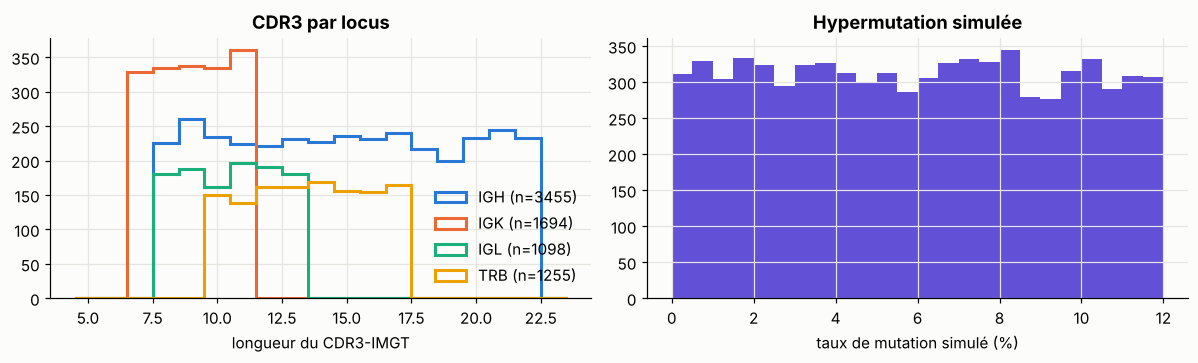

In [16]:
rows = [dict(locus=dom["locus"], species=dom["species"], shm=dom["shm_rate"],
             cdr3_len=sum(r == "CDR3" for r in d["regions"][dom["start"]:dom["end"]]))
        for d in data for dom in d["domains"] if dom["type"] == "V"]
dv = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for k, locus in enumerate(LOCI):
    sub = dv[dv.locus == locus]
    axes[0].hist(sub.cdr3_len, bins=np.arange(4.5, 24.5), histtype="step", lw=2, color=PALETTE[k], label=f"{locus} (n={len(sub)})")
axes[0].set_xlabel("longueur du CDR3-IMGT"); axes[0].legend(); axes[0].set_title("CDR3 par locus")
axes[1].hist(dv.shm * 100, bins=24, color=PALETTE[6]); axes[1].set_xlabel("taux de mutation simulé (%)")
axes[1].set_title("Hypermutation simulée")
plt.tight_layout(); plt.show()
print(pd.Series(Counter(d["kind"] for d in data)).to_string())

**Export** en JSON Lines, un enregistrement par séquence. On sauvegarde aussi le répertoire de référence (pour la méthode par alignement du notebook 3) et une **fiche de jeu de données** minimale : d'où viennent les données, quelle version, combien d'exemples. Dans le vrai projet, note la **version de la release IMGT** : une publication doit être reproductible avec une version figée.

In [17]:
def save_jsonl(records, path):
    import json
    with open(path, "w") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")


def load_jsonl(path):
    import json
    with open(path) as f:
        return [json.loads(line) for line in f]

In [18]:
from protannotml.synth import save_jsonl
save_jsonl(data, DATA / "examples.jsonl")
save_jsonl(refs, DATA / "reference_V.jsonl")
save_jsonl(j_genes, DATA / "reference_J.jsonl")
save_jsonl(c_domains, DATA / "reference_C.jsonl")
card = dict(name="ProtAnnotML synthetic development set", source="protannotml.synth (fictional sequences)",
            imgt_release="n/a (synthetic)", seeds=dict(reference=0, examples=1), n_examples=len(data),
            n_v_alleles=len(refs), kinds=dict(Counter(d["kind"] for d in data)))
(DATA / "DATASET_CARD.json").write_text(json.dumps(card, indent=2))
print(sorted(p.name for p in DATA.iterdir()))

['DATASET_CARD.json', 'DEMO-ReferenceSequences.fasta-AA-WithGaps', 'examples.jsonl', 'reference_C.jsonl', 'reference_J.jsonl', 'reference_V.jsonl', 'splits.json']


## 7. Les vraies données : sorties AIRR d'IMGT/HighV-QUEST

Pour des séquences réarrangées réelles (IMGT/LIGM-DB, répertoires, anticorps thérapeutiques), le plus simple est de les annoter avec **IMGT/HighV-QUEST** et d'utiliser la sortie au format **AIRR** (une ligne par séquence, colonnes standardisées) : `sequence_id`, `locus`, `v_call`, `j_call`, `productive`, `sequence_alignment_aa` (alignement avec gaps IMGT), et les régions `fwr1_aa`, `cdr1_aa`, …, `fwr4_aa`.

Construire les étiquettes à partir de ces colonnes a un piège : selon l'outil et les options, l'alignement peut commencer après la position 1 (séquence tronquée), le CDR3 n'est pas numéroté explicitement, et `v_call` peut contenir **plusieurs** allèles séparés par des virgules (ambiguïté, encore). La fonction ci-dessous fait le travail **et se vérifie elle-même** : les régions reconstruites depuis l'alignement doivent coïncider avec les colonnes de régions ; sinon la ligne est rejetée et comptée.

In [19]:
AIRR_REGION_COLUMNS = [("FR1", "fwr1_aa"), ("CDR1", "cdr1_aa"), ("FR2", "fwr2_aa"), ("CDR2", "cdr2_aa"),
                       ("FR3", "fwr3_aa"), ("CDR3", "cdr3_aa"), ("FR4", "fwr4_aa")]


def airr_row_to_v_domain(row):
    """AIRR rearrangement row (dict) -> list of (IMGT position, aa) for the V domain, or raise ValueError.

    FR1-FR3 / CDR1-CDR2 positions come from the IMGT-gapped `sequence_alignment_aa` (assumed to start at
    position 1, missing 5' positions shown as '.'); CDR3 is numbered with the IMGT length rule; FR4 from 118.
    """
    gapped = row["sequence_alignment_aa"]
    v_part = gapped[:104]
    residues = [(str(i + 1), aa) for i, aa in enumerate(v_part) if aa not in ".-"]
    cdr3, fr4 = row.get("cdr3_aa") or "", row.get("fwr4_aa") or ""
    residues += list(zip(cdr_positions("CDR3", len(cdr3)), cdr3))
    residues += [(str(118 + i), aa) for i, aa in enumerate(fr4)]
    rebuilt = defaultdict(str)
    for p, aa in residues:
        rebuilt[region_of(p)] += aa
    for region, col in AIRR_REGION_COLUMNS:
        if (row.get(col) or "") != rebuilt.get(region, ""):
            raise ValueError(f"{row.get('sequence_id')}: {region} mismatch ({row.get(col)!r} vs {rebuilt.get(region, '')!r})")
    return residues

In [20]:
from protannotml.imgt import airr_row_to_v_domain, AIRR_REGION_COLUMNS

# Build two AIRR-like rows from our synthetic data: one consistent, one with a corrupted region column
dom = next(dm for d in data for dm in d["domains"] if dm["type"] == "V" and dm["locus"] == "IGH")
d0 = next(d for d in data if dom in d["domains"])
pos, aa = d0["imgt_pos"][dom["start"]:dom["end"]], d0["seq"][dom["start"]:dom["end"]]
at = dict(zip(pos, aa))
row = {"sequence_id": d0["id"], "locus": "IGH", "v_call": dom["v_allele"], "j_call": dom["j_gene"] + "*01",
       "sequence_alignment_aa": "".join(at.get(str(p), ".") for p in range(1, 105))}
for region, col in AIRR_REGION_COLUMNS:
    row[col] = "".join(a for p, a in zip(pos, aa) if region_of(p) == region)
bad = dict(row, cdr2_aa=row["cdr2_aa"][:-1])

ok = airr_row_to_v_domain(row)
print("consistent row ->", len(ok), "residues, identical to the labels:", ok == list(zip(pos, aa)))
try:
    airr_row_to_v_domain(bad)
except ValueError as e:
    print("corrupted row rejected:", e)

consistent row -> 120 residues, identical to the labels: True
corrupted row rejected: seq00000: CDR2 mismatch ('NKFKWY' vs 'NKFKWYL')


Pour une table complète (`vquest_airr.tsv`), on lit avec pandas, on garde les lignes productives, et on **compte** les rejets par cause : un taux de rejet élevé indique une hypothèse fausse (par exemple un alignement qui ne commence pas en position 1).

In [ ]:
airr = pd.read_csv("vquest_airr.tsv", sep="\t", dtype=str).fillna("")
airr = airr[airr["productive"].isin(["T", "TRUE", "True", "true"])]
records, rejected = [], Counter()
for row in airr.to_dict("records"):
    try:
        residues = airr_row_to_v_domain(row)
    except (ValueError, KeyError) as e:
        rejected[type(e).__name__ + ": " + str(e).split(":")[1][:20]] += 1
        continue
    v_alleles = sorted(a.strip() for a in row["v_call"].split(","))          # ambiguous calls -> label set
    records.append(dict(id=row["sequence_id"], seq="".join(a for _, a in residues),
                        imgt_pos=[p for p, _ in residues], regions=[region_of(p) for p, _ in residues],
                        domain_tags=["B-V"] + ["I-V"] * (len(residues) - 1),
                        domains=[dict(type="V", start=0, end=len(residues), locus=row["locus"],
                                      v_allele=v_alleles[0], allele_set=v_alleles, j_gene=row["j_call"].split("*")[0])]))
print(len(records), "records;", sum(rejected.values()), "rejected:", rejected.most_common(5))

> 🔎 **Conseil de relecteur.** Les étiquettes produites par IMGT/HighV-QUEST sont elles-mêmes issues d'un **alignement**. Un modèle entraîné dessus apprend à **imiter** l'outil, erreurs comprises, et ne peut pas, en principe, le dépasser sur ces mêmes étiquettes. Prévois un **jeu de test expertisé** (séquences annotées et vérifiées manuellement par l'équipe IMGT, par exemple celles d'IMGT/mAb-DB et d'IMGT/3Dstructure-DB), et rapporte-le séparément : c'est là que tu pourras montrer un vrai gain.

## 8. Récapitulatif

| Élément | À retenir |
|---|---|
| Tâches | T1 domaines (BIO), T2 régions, T3 numérotation, T4 locus/gène/allèle/espèce |
| Contraintes | régions ordonnées et positions croissantes : décodage structuré nécessaire |
| Numérotation | gaps au sommet des boucles (ordres fixes), insertions 111.x / 112.x pour CDR3 > 13 |
| Fichiers IMGT | en-tête à 15 champs ; dans les fichiers avec gaps, indice = position IMGT |
| Données réalistes | réarrangées, mutées, tronquées, multi-domaines ; pas seulement des germlines |
| Ambiguïtés | ensembles d'allèles/gènes identiques ; appels multiples dans `v_call` |
| Traçabilité | version IMGT, graines, fiche de jeu de données, contrôles automatiques |

### 🏋️ Exercices

1. **Vrais fichiers.** Lis le fichier IMGT/GENE-DB AA-WithGaps (F+ORF+inframeP), et compte par locus et par espèce : allèles, gènes, enregistrements partiels, ancres absentes. Combien d'allèles partagent leur séquence protéique avec un autre allèle ? avec un autre **gène** ?
2. **Constructions.** Ajoute un format bispécifique (deux scFv) et un format VHH (domaine V de chaîne lourde seul, avec les substitutions caractéristiques du FR2). Vérifie avec `check_example`.
3. **Taux de rejet AIRR.** Sur une vraie sortie d'IMGT/HighV-QUEST, mesure le taux de rejet de `airr_row_to_v_domain` et identifie la première cause. Corrige l'hypothèse fautive (et non le contrôle).
4. **Biais de germline.** Mesure, dans tes données d'entraînement réelles, la proportion de séquences issues de répertoires naïfs (peu mutées). Que risque un modèle entraîné dessus sur des anticorps thérapeutiques (voir AbLang-2 dans la liste de lecture) ?

<details><summary>Indications</summary>

2. Pour le VHH, les positions 42, 49, 50 et 52 du FR2-IMGT portent typiquement des résidus hydrophiles ; dans le générateur, il suffit de muter ces positions sur des allèles IGH et d'ajouter un type de construction.
4. Une forte proportion de séquences peu mutées pousse le modèle à prédire la germline et à sous-estimer la diversité des CDR mutés ; stratifie l'évaluation par taux de mutation (notebook 5) et envisage une perte focale ou une repondération.
</details>